In [13]:
import os
import glob
import numpy as np
import pandas as pd
# import cv2  # OpenCV est souvent plus rapide pour les calculs de moments
from skimage import io, color, filters, measure, morphology
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, f1_score, classification_report
try:
    from xgboost import XGBClassifier
except ImportError:
    print("Erreur: Installe xgboost avec 'pip install xgboost'")
from tqdm import tqdm

# === CONFIGURATION ===
TRAIN_DIR = "/home/lmalerba/projects/kaggle_challenge_sdi/data/original_dataset_optimized_512px/train/"  # <--- METTRE TON CHEMIN ICI
DARK_OBJECT = True 
PERMISSIVITE = 1.15
MAX_SAMPLES_PER_CLASS = 500  # Limite pour tester vite (mets None pour tout faire)
import warnings


# def get_features_from_image(img_path):
#     """
#     Lit une image, segmente le plancton et extrait un riche set de features (20+).
#     Version optimisée sans warnings.
#     """
#     with warnings.catch_warnings():
#         warnings.simplefilter("ignore", category=FutureWarning)
        
#         try:
#             # --- 1. PRÉTRAITEMENT ---
#             img = io.imread(img_path)
#             if img.ndim == 3:
#                 gray = color.rgb2gray(img)
#             else:
#                 gray = img
#                 if gray.dtype == np.uint8:
#                     gray = gray / 255.0

#             # --- 2. SEGMENTATION (Otsu Relax) ---
#             val_otsu = filters.threshold_otsu(gray)
            
#             if DARK_OBJECT:
#                 val_relax = min(val_otsu * PERMISSIVITE, 0.99)
#                 mask = gray < val_relax
#             else:
#                 val_relax = max(val_otsu * (2 - PERMISSIVITE), 0.01)
#                 mask = gray > val_relax

#             mask = morphology.remove_small_objects(mask, 50)
            
#             if not np.any(mask):
#                 return None

#             # --- 3. EXTRACTION ---
#             labels = measure.label(mask)
#             regions = measure.regionprops(labels, intensity_image=gray)
            
#             if not regions:
#                 return None
                
#             # On prend le plus gros objet
#             props = max(regions, key=lambda r: r.area)
            
#             # --- COMPATIBILITÉ VERSION (SKIMAGE) ---
#             # Axe Majeur
#             if hasattr(props, 'axis_major_length'): major = props.axis_major_length
#             else: major = props.major_axis_length
                
#             # Axe Mineur
#             if hasattr(props, 'axis_minor_length'): minor = props.axis_minor_length
#             else: minor = props.minor_axis_length
                
#             # Intensité Moyenne
#             if hasattr(props, 'intensity_mean'): mean_val = props.intensity_mean
#             else: mean_val = props.mean_intensity

#             # Intensité Max
#             if hasattr(props, 'intensity_max'): max_val = props.intensity_max
#             else: max_val = props.max_intensity

#             # Intensité Min
#             if hasattr(props, 'intensity_min'): min_val = props.intensity_min
#             else: min_val = props.min_intensity

#             # --- FEATURES CALCULÉES ---
            
#             # 1. Écart-type de l'intensité (Texture/Transparence)
#             # On récupère les pixels qui sont DANS le masque uniquement
#             pixels_values = gray[mask]
#             std_val = np.std(pixels_values) if len(pixels_values) > 0 else 0

#             # 2. Moments de Hu (Invariants de forme très puissants)
#             hu = props.moments_hu

#             features = {
#                 # --- Basiques ---
#                 "area": props.area,
#                 "perimeter": props.perimeter,
#                 "major_axis": major,
#                 "minor_axis": minor,
#                 "eccentricity": props.eccentricity,
#                 "solidity": props.solidity,
                
#                 # --- Rapports de forme ---
#                 "aspect_ratio": major / (minor + 1e-6),
#                 "circularity": (4 * np.pi * props.area) / (props.perimeter**2 + 1e-6),
#                 "extent": props.extent,  # Aire / Aire Bounding Box
#                 "equivalent_diameter": props.equivalent_diameter,
#                 "convex_area": props.convex_area,
                
#                 # --- Texture & Intensité ---
#                 "mean_intensity": mean_val,
#                 "max_intensity": max_val,
#                 "min_intensity": min_val,
#                 "std_intensity": std_val, # Contraste interne
#                 "orientation": props.orientation,

#                 # --- Moments de Hu (Forme abstraite) ---
#                 "hu_0": hu[0],
#                 "hu_1": hu[1],
#                 "hu_2": hu[2],
#                 "hu_3": hu[3],
#                 "hu_4": hu[4],
#                 "hu_5": hu[5],
#                 "hu_6": hu[6],
#             }
            
#             return features

#         except Exception as e:
#             return None

# import warnings
# from skimage import io, color, filters, measure, morphology
# import numpy as np
# import scipy.stats as stats  # <--- Ajout important pour Skewness/Kurtosis

# def get_features_from_image(img_path):
#     """
#     Extraction avancée type 'ZooScan'.
#     Combine géométrie, moments de Hu, quartiles d'histo et distribution spatiale.
#     """
#     with warnings.catch_warnings():
#         warnings.simplefilter("ignore", category=FutureWarning)
        
#         try:
#             # --- 1. PRÉTRAITEMENT ---
#             img = io.imread(img_path)
#             if img.ndim == 3:
#                 gray = color.rgb2gray(img)
#             else:
#                 gray = img
#                 if gray.dtype == np.uint8:
#                     gray = gray / 255.0

#             # --- 2. SEGMENTATION ---
#             val_otsu = filters.threshold_otsu(gray)
            
#             if DARK_OBJECT:
#                 val_relax = min(val_otsu * PERMISSIVITE, 0.99)
#                 mask = gray < val_relax
#             else:
#                 val_relax = max(val_otsu * (2 - PERMISSIVITE), 0.01)
#                 mask = gray > val_relax

#             mask = morphology.remove_small_objects(mask, 50) # Nettoyage bruit
            
#             if not np.any(mask):
#                 return None

#             # --- 3. PROPRIÉTÉS ---
#             # On demande explicitement les regionprops nécessaires + images pour calculs avancés
#             labels = measure.label(mask)
#             regions = measure.regionprops(labels, intensity_image=gray)
            
#             if not regions:
#                 return None
            
#             props = max(regions, key=lambda r: r.area) # Le plus gros objet

#             # --- 4. CALCULS BASIQUES & COMPATIBILITÉ ---
#             # Gestion des noms changeants dans Skikit-Image
#             major = props.axis_major_length if hasattr(props, 'axis_major_length') else props.major_axis_length
#             minor = props.axis_minor_length if hasattr(props, 'axis_minor_length') else props.minor_axis_length
#             mean_val = props.intensity_mean if hasattr(props, 'intensity_mean') else props.mean_intensity

#             # --- 5. FEATURES AVANCÉES (LA PARTIE MANQUANTE) ---
            
#             # A. Statistiques de distribution des gris (Texture fine)
#             # On extrait les pixels de l'objet uniquement
#             intensities = gray[mask]
            
#             if len(intensities) > 0:
#                 skew_val = stats.skew(intensities)       # Asymétrie de l'histo
#                 kurt_val = stats.kurtosis(intensities)   # Aplatissement de l'histo
                
#                 # Percentiles (Hist25, Hist50, Hist75)
#                 p25, p50, p75 = np.percentile(intensities, [25, 50, 75])
#             else:
#                 skew_val, kurt_val, p25, p50, p75 = 0, 0, 0, 0, 0

#             # B. Distance du Centroid (cdist)
#             # Différence entre le centre géométrique et le centre de masse (pondéré par gris)
#             y0, x0 = props.centroid
#             if hasattr(props, 'weighted_centroid'):
#                 yw, xw = props.weighted_centroid
#                 # Distance Euclidienne
#                 cdist = np.sqrt((x0 - xw)**2 + (y0 - yw)**2)
#             else:
#                 cdist = 0.0 # Fallback si version trop vieille
                
#             # C. Moments de Hu (Forme pure)
#             hu = props.moments_hu

#             # --- 6. CONSTRUCTION DICTIONNAIRE FINAL ---
#             features = {
#                 # Géométrie
#                 "area": props.area,
#                 "perimeter": props.perimeter,
#                 "major_axis": major,
#                 "minor_axis": minor,
#                 "elongation": major / (minor + 1e-6), # Plus parlant que aspect_ratio
#                 "eccentricity": props.eccentricity,
#                 "solidity": props.solidity, # Detecte les contours irréguliers/poilus
#                 "extent": props.extent,     # Rectangularité
#                 "circularity": (4 * np.pi * props.area) / (props.perimeter**2 + 1e-6),
                
#                 # Densité & Texture (ZooProcess Core)
#                 "mean_intensity": mean_val,
#                 "std_intensity": np.std(intensities),
#                 "min_intensity": np.min(intensities) if len(intensities) > 0 else 0,
#                 "max_intensity": np.max(intensities) if len(intensities) > 0 else 0,
                
#                 # Distribution avancée (Nouveaux ajouts essentiels)
#                 "skewness": skew_val, # Distribution unilatérale ?
#                 "kurtosis": kurt_val, # Pics d'intensité ?
#                 "hist_25": p25,       # Les tons sombres
#                 "hist_50": p50,       # La médiane
#                 "hist_75": p75,       # Les tons clairs
                
#                 # Masse & Symétrie
#                 "cdist": cdist,       # Asymétrie de densité (Tête vs Queue)
#                 "euler_number": props.euler_number, # Nombre de trous (ex: anneaux)

#                 # Moments de Hu (Invariant rotation/échelle)
#                 "hu_0": hu[0], "hu_1": hu[1], "hu_2": hu[2],
#                 "hu_3": hu[3], "hu_4": hu[4], "hu_5": hu[5], "hu_6": hu[6],
#             }
            
#             return features

#         except Exception as e:
#             # print(f"Erreur sur {img_path}: {e}") # Debug si besoin
#             return None

import warnings
from skimage import io, color, filters, measure, morphology
import numpy as np
import scipy.stats as stats  # <--- Ajout important pour Skewness/Kurtosis

def get_features_from_image(img_path):
    """
    Extraction avancée type 'ZooScan'.
    Combine géométrie, moments de Hu, quartiles d'histo et distribution spatiale.
    """
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", category=FutureWarning)
        
        try:
            # --- 1. PRÉTRAITEMENT ---
            img = io.imread(img_path)
            if img.ndim == 3:
                gray = color.rgb2gray(img)
            else:
                gray = img
                if gray.dtype == np.uint8:
                    gray = gray / 255.0

            # --- 2. SEGMENTATION ---
            val_otsu = filters.threshold_otsu(gray)
            
            if DARK_OBJECT:
                val_relax = min(val_otsu * PERMISSIVITE, 0.99)
                mask = gray < val_relax
            else:
                val_relax = max(val_otsu * (2 - PERMISSIVITE), 0.01)
                mask = gray > val_relax

            mask = morphology.remove_small_objects(mask, 50) # Nettoyage bruit
            
            if not np.any(mask):
                return None

            # --- 3. PROPRIÉTÉS ---
            # On demande explicitement les regionprops nécessaires + images pour calculs avancés
            labels = measure.label(mask)
            regions = measure.regionprops(labels, intensity_image=gray)
            
            if not regions:
                return None
            
            props = max(regions, key=lambda r: r.area) # Le plus gros objet

            # --- 4. CALCULS BASIQUES & COMPATIBILITÉ ---
            # Gestion des noms changeants dans Skikit-Image
            major = props.axis_major_length if hasattr(props, 'axis_major_length') else props.major_axis_length
            minor = props.axis_minor_length if hasattr(props, 'axis_minor_length') else props.minor_axis_length
            mean_val = props.intensity_mean if hasattr(props, 'intensity_mean') else props.mean_intensity

            # --- 5. FEATURES AVANCÉES (LA PARTIE MANQUANTE) ---
            
            # A. Statistiques de distribution des gris (Texture fine)
            # On extrait les pixels de l'objet uniquement
            intensities = gray[mask]
            
            if len(intensities) > 0:
                skew_val = stats.skew(intensities)       # Asymétrie de l'histo
                kurt_val = stats.kurtosis(intensities)   # Aplatissement de l'histo
                
                # Percentiles (Hist25, Hist50, Hist75)
                p25, p50, p75 = np.percentile(intensities, [25, 50, 75])
            else:
                skew_val, kurt_val, p25, p50, p75 = 0, 0, 0, 0, 0

            # B. Distance du Centroid (cdist)
            # Différence entre le centre géométrique et le centre de masse (pondéré par gris)
            y0, x0 = props.centroid
            if hasattr(props, 'weighted_centroid'):
                yw, xw = props.weighted_centroid
                # Distance Euclidienne
                cdist = np.sqrt((x0 - xw)**2 + (y0 - yw)**2)
            else:
                cdist = 0.0 # Fallback si version trop vieille
                
            # C. Moments de Hu (Forme pure)
            hu = props.moments_hu

            # --- 6. CONSTRUCTION DICTIONNAIRE FINAL ---
            features = {
                # Géométrie
                "area": props.area,
                "perimeter": props.perimeter,
                "major_axis": major,
                "minor_axis": minor,
                "elongation": major / (minor + 1e-6), # Plus parlant que aspect_ratio
                "eccentricity": props.eccentricity,
                "solidity": props.solidity, # Detecte les contours irréguliers/poilus
                "extent": props.extent,     # Rectangularité
                "circularity": (4 * np.pi * props.area) / (props.perimeter**2 + 1e-6),
                
                # Densité & Texture (ZooProcess Core)
                "mean_intensity": mean_val,
                "std_intensity": np.std(intensities),
                "min_intensity": np.min(intensities) if len(intensities) > 0 else 0,
                "max_intensity": np.max(intensities) if len(intensities) > 0 else 0,
                
                # Distribution avancée (Nouveaux ajouts essentiels)
                "skewness": skew_val, # Distribution unilatérale ?
                "kurtosis": kurt_val, # Pics d'intensité ?
                "hist_25": p25,       # Les tons sombres
                "hist_50": p50,       # La médiane
                "hist_75": p75,       # Les tons clairs
                
                # Masse & Symétrie
                "cdist": cdist,       # Asymétrie de densité (Tête vs Queue)
                "euler_number": props.euler_number, # Nombre de trous (ex: anneaux)

                # Moments de Hu (Invariant rotation/échelle)
                "hu_0": hu[0], "hu_1": hu[1], "hu_2": hu[2],
                "hu_3": hu[3], "hu_4": hu[4], "hu_5": hu[5], "hu_6": hu[6],
            }
            
            return features

        except Exception as e:
            # print(f"Erreur sur {img_path}: {e}") # Debug si besoin
            return None




# =============================================================================
# 1. CONSTRUCTION DU DATASET (DataFrame)
# =============================================================================

data_list = []
classes = [d for d in os.listdir(TRAIN_DIR) if os.path.isdir(os.path.join(TRAIN_DIR, d))]

print(f"Classes trouvées : {len(classes)}")

for class_name in tqdm(classes, desc="Parcours des classes"):
    class_dir = os.path.join(TRAIN_DIR, class_name)
    images = glob.glob(os.path.join(class_dir, "*.jpg")) + glob.glob(os.path.join(class_dir, "*.png"))

    # Sampling si demandé
    if MAX_SAMPLES_PER_CLASS and len(images) > MAX_SAMPLES_PER_CLASS:
        images = np.random.choice(images, MAX_SAMPLES_PER_CLASS, replace=False)

    for img_path in images:
        feats = get_features_from_image(img_path)
        if feats is not None:
            feats['target'] = class_name   # On ajoute la cible
            feats['filename'] = img_path   # <--- AJOUT : On garde le chemin du fichier
            data_list.append(feats)

# Création du DataFrame
df = pd.DataFrame(data_list)
print(f"\nDataset créé : {df.shape[0]} images, {df.shape[1]} colonnes")
print(df.head())

# =============================================================================
# 2. PRÉPARATION POUR XGBOOST
# =============================================================================

# Séparation X (Features), y (Cible) et files (Noms de fichiers)
# On retire 'target' ET 'filename' des features d'entraînement
X = df.drop(columns=['target', 'filename'])
y_str = df['target']
files = df['filename']  # <--- AJOUT : On isole la colonne des chemins

# Encodage des labels (Copepoda -> 0, Decapoda -> 1...)
le = LabelEncoder()
y = le.fit_transform(y_str)

# Split Train / Test (On passe 'files' en 3ème argument)
# La fonction va splitter X, y ET files de la même manière (mêmes index)
X_train, X_test, y_train, y_test, files_train, files_test = train_test_split(
    X, y, files, test_size=0.2, random_state=42, stratify=y
)

print(f"\nEntraînement sur {len(X_train)} exemples, Test sur {len(X_test)} exemples.")
# Maintenant tu as files_test disponible pour la visualisation des erreurs !


Classes trouvées : 86


Parcours des classes: 100%|██████████| 86/86 [06:23<00:00,  4.46s/it]



Dataset créé : 35339 images, 29 colonnes
     area   perimeter  major_axis  minor_axis  elongation  eccentricity  \
0   533.0   96.911688   32.332782   22.587170    1.431467      0.715528   
1  1023.0  192.716775   61.475822   25.638881    2.397758      0.908881   
2   698.0  127.639610   51.342057   19.397134    2.646889      0.925886   
3   578.0  124.675144   45.044051   18.662590    2.413601      0.910132   
4   668.0  132.775649   44.929162   22.364385    2.008960      0.867309   

   solidity    extent  circularity  mean_intensity  ...  euler_number  \
0  0.901861  0.643720     0.713156        0.533120  ...             1   
1  0.700205  0.410678     0.346136        0.484350  ...             1   
2  0.879093  0.516272     0.538387        0.607130  ...             1   
3  0.811798  0.421283     0.467281        0.597958  ...             1   
4  0.800959  0.535256     0.476156        0.466808  ...             1   

       hu_0      hu_1      hu_2      hu_3          hu_4      hu_5  \

In [14]:
from xgboost import XGBClassifier
# =============================================================================
# 3. ENTRAÎNEMENT XGBOOST
# =============================================================================

# Configuration simple mais robuste
model = XGBClassifier(
    n_estimators=10,      # Nombre d'arbres
    learning_rate=0.05,    # Vitesse d'apprentissage
    max_depth=6,           # Profondeur des arbres
    subsample=0.8,         # Utilise 80% des données par arbre (évite overfitting)
    colsample_bytree=0.8,  # Utilise 80% des features par arbre
    n_jobs=-1,             # Utilise tous les coeurs CPU
    random_state=42
)

print("Lancement de l'entraînement XGBoost...")
model.fit(X_train, y_train, eval_set=[(X_test, y_test)],  # Il teste son niveau sur le test set en direct
    verbose=10)


Lancement de l'entraînement XGBoost...


[0]	validation_0-mlogloss:3.96933
[9]	validation_0-mlogloss:2.83942


,"objective objective: typing.Union[str, xgboost.sklearn._SklObjWProto, typing.Callable[[typing.Any, typing.Any], typing.Tuple[numpy.ndarray, numpy.ndarray]], NoneType]Specify the learning task and the corresponding learning objective or a customobjective function to be used.For custom objective, see :doc:`/tutorials/custom_metric_obj` and:ref:`custom-obj-metric` for more information, along with the end note forfunction signatures.",'multi:softprob'
,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API `... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,0.8
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,False
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes fr

In [17]:

# =============================================================================
# 4. ÉVALUATION
# =============================================================================

y_pred = model.predict(X_test)

acc = accuracy_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred, average='weighted')

print("-" * 30)
print(f"RÉSULTATS XGBOOST (HANDCRAFTED FEATURES)")
print("-" * 30)
print(f"Accuracy : {acc:.4f}")
print(f"F1-Score : {f1:.4f}")
print("-" * 30)

# Afficher quelles features sont les plus importantes
importances = model.feature_importances_
indices = np.argsort(importances)[::-1]

print("\nTop 5 Features les plus importantes :")
for i in range(5):
    idx = indices[i]
    print(f"{i+1}. {X.columns[idx]} ({importances[idx]:.4f})")


------------------------------
RÉSULTATS XGBOOST (HANDCRAFTED FEATURES)
------------------------------
Accuracy : 0.5256
F1-Score : 0.5112
------------------------------

Top 5 Features les plus importantes :
1. hu_0 (0.0631)
2. area (0.0559)
3. major_axis (0.0498)
4. perimeter (0.0479)
5. hu_3 (0.0471)


V1: 9 features sur le dataset original optimisé
Classes trouvées : 86
Lancement de l'entraînement XGBoost...
[0]	validation_0-mlogloss:4.09206
[9]	validation_0-mlogloss:3.07135
------------------------------
RÉSULTATS XGBOOST (HANDCRAFTED FEATURES)
------------------------------
Accuracy : 0.4373
F1-Score : 0.4069
------------------------------

Top 5 Features les plus importantes :
1. mean_intensity (0.1322)
2. area (0.1254)
3. perimeter (0.1245)
4. eccentricity (0.1204)
5. aspect_ratio (0.1118)

V2: 27 features sur le dataset original optimisé:

Classes trouvées : 86
Parcours des classes: 100%|██████████| 86/86 [04:08<00:00,  2.89s/it]

Dataset créé : 35352 images, 24 colonnes
    area   perimeter  major_axis  minor_axis  eccentricity  solidity  \
0  833.0  166.675144   60.810532   20.200436      0.943214  0.767035   
1  680.0  133.053824   51.111324   18.830168      0.929662  0.853199   
2  539.0  108.876154   37.793809   19.935939      0.849560  0.833076   
3  645.0  123.468037   43.670879   21.998608      0.863857  0.829049   
4  837.0  160.681241   55.943528   21.878543      0.920356  0.784442   

   aspect_ratio  circularity    extent  equivalent_diameter  ...  \
0      3.010357     0.376802  0.394413            32.566985  ...   
1      2.714332     0.482685  0.515152            29.424529  ...   
2      1.895763     0.571391  0.495404            26.196872  ...   
3      1.985165     0.531692  0.572316            28.657277  ...   
4      2.557004     0.407385  0.437304            32.645084  ...   

   std_intensity  orientation      hu_0      hu_1      hu_2      hu_3  \
0       0.161513     1.263161  0.308072  0.060929  0.008219  0.004201   
1       0.180196    -1.322608  0.272697  0.043064  0.005201  0.002636   
2       0.163545    -0.886938  0.211713  0.014290  0.001185  0.000350   
3       0.167983     0.002655  0.231694  0.019019  0.003971  0.001484   
4       0.159807    -0.392457  0.269441  0.039186  0.004978  0.001997   

           hu_4      hu_5          hu_6      target  
0  2.459227e-05  0.001002 -2.109580e-06  010_Oncaea  
...

[5 rows x 24 columns]

Entraînement sur 28281 exemples, Test sur 7071 exemples.
Output is truncated. View as a scrollable element or open in a text editor. Adjust cell output settings...
Lancement de l'entraînement XGBoost...
[0]	validation_0-mlogloss:3.99589
[9]	validation_0-mlogloss:2.89976
------------------------------
RÉSULTATS XGBOOST (HANDCRAFTED FEATURES)
------------------------------
Accuracy : 0.5028
F1-Score : 0.4832
------------------------------

Top 5 Features les plus importantes :
1. equivalent_diameter (0.0732)
2. hu_0 (0.0703)
3. perimeter (0.0640)
4. area (0.0613)
5. mean_intensity (0.0581)

V3: encore plus de features:
Lancement de l'entraînement XGBoost...
[0]	validation_0-mlogloss:3.96096
[9]	validation_0-mlogloss:2.82335
------------------------------
RÉSULTATS XGBOOST (HANDCRAFTED FEATURES)
------------------------------
Accuracy : 0.5352
F1-Score : 0.5177
------------------------------

Top 5 Features les plus importantes :
1. hu_0 (0.0615)
2. area (0.0579)
3. major_axis (0.0516)
4. perimeter (0.0507)
5. hu_1 (0.0476)

V4: Features dédoublées otsu + triangle


 VISUALISATION DES ERREURS (MODEL FAILS)
Nombre total d'erreurs : 3353 sur 7068 images de test.
Affichage de 10 exemples d'erreurs...



/tmp/ipykernel_1019/575614534.py:71: FutureWarning: Parameter `min_size` is deprecated since version 0.26.0 and will be removed in 2.0.0 (or later). To avoid this warning, please use the parameter `max_size` instead. For more details, see the documentation of `remove_small_objects`. Note that the new threshold removes objects smaller than **or equal to** its value, while the previous parameter only removed smaller ones.
  mask = morphology.remove_small_objects(mask, 50)


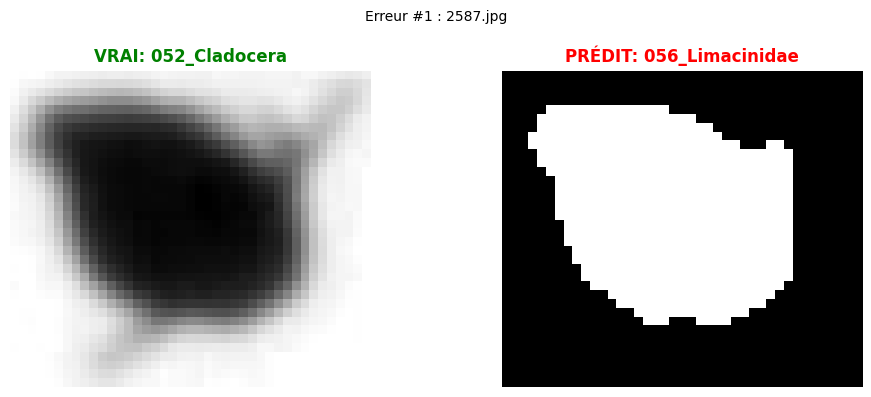

/tmp/ipykernel_1019/575614534.py:71: FutureWarning: Parameter `min_size` is deprecated since version 0.26.0 and will be removed in 2.0.0 (or later). To avoid this warning, please use the parameter `max_size` instead. For more details, see the documentation of `remove_small_objects`. Note that the new threshold removes objects smaller than **or equal to** its value, while the previous parameter only removed smaller ones.
  mask = morphology.remove_small_objects(mask, 50)


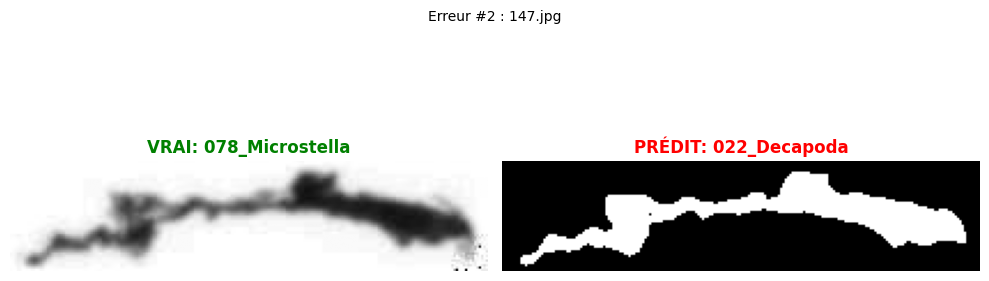

/tmp/ipykernel_1019/575614534.py:71: FutureWarning: Parameter `min_size` is deprecated since version 0.26.0 and will be removed in 2.0.0 (or later). To avoid this warning, please use the parameter `max_size` instead. For more details, see the documentation of `remove_small_objects`. Note that the new threshold removes objects smaller than **or equal to** its value, while the previous parameter only removed smaller ones.
  mask = morphology.remove_small_objects(mask, 50)


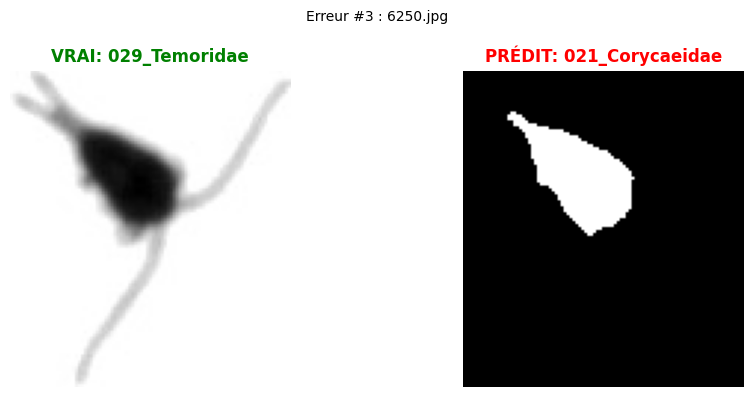

/tmp/ipykernel_1019/575614534.py:71: FutureWarning: Parameter `min_size` is deprecated since version 0.26.0 and will be removed in 2.0.0 (or later). To avoid this warning, please use the parameter `max_size` instead. For more details, see the documentation of `remove_small_objects`. Note that the new threshold removes objects smaller than **or equal to** its value, while the previous parameter only removed smaller ones.
  mask = morphology.remove_small_objects(mask, 50)


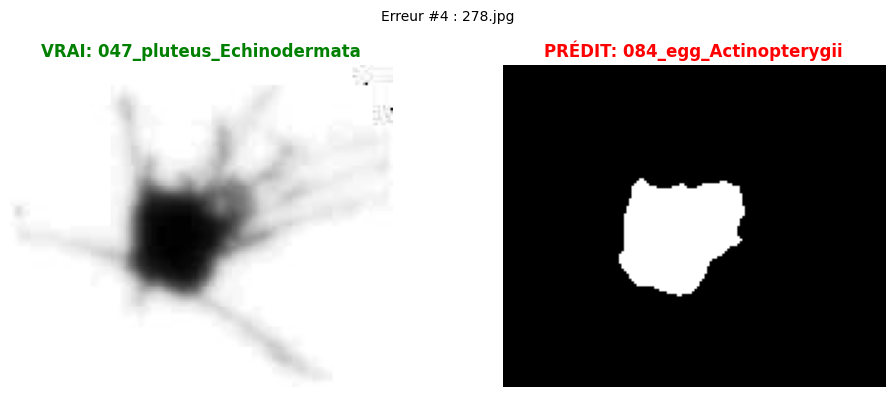

/tmp/ipykernel_1019/575614534.py:71: FutureWarning: Parameter `min_size` is deprecated since version 0.26.0 and will be removed in 2.0.0 (or later). To avoid this warning, please use the parameter `max_size` instead. For more details, see the documentation of `remove_small_objects`. Note that the new threshold removes objects smaller than **or equal to** its value, while the previous parameter only removed smaller ones.
  mask = morphology.remove_small_objects(mask, 50)


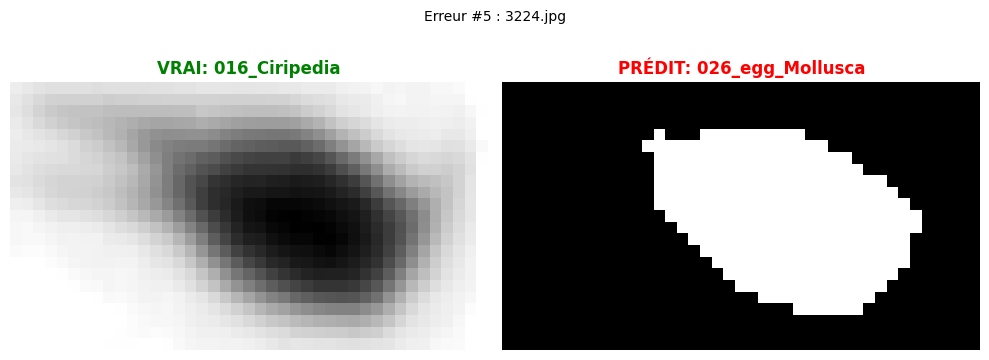

/tmp/ipykernel_1019/575614534.py:71: FutureWarning: Parameter `min_size` is deprecated since version 0.26.0 and will be removed in 2.0.0 (or later). To avoid this warning, please use the parameter `max_size` instead. For more details, see the documentation of `remove_small_objects`. Note that the new threshold removes objects smaller than **or equal to** its value, while the previous parameter only removed smaller ones.
  mask = morphology.remove_small_objects(mask, 50)


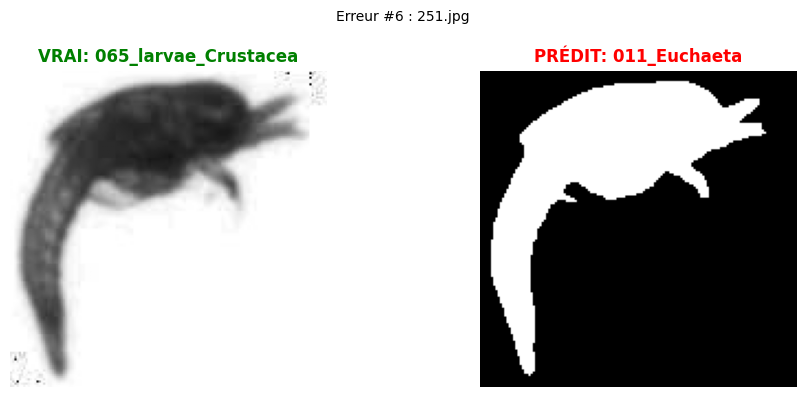

/tmp/ipykernel_1019/575614534.py:71: FutureWarning: Parameter `min_size` is deprecated since version 0.26.0 and will be removed in 2.0.0 (or later). To avoid this warning, please use the parameter `max_size` instead. For more details, see the documentation of `remove_small_objects`. Note that the new threshold removes objects smaller than **or equal to** its value, while the previous parameter only removed smaller ones.
  mask = morphology.remove_small_objects(mask, 50)


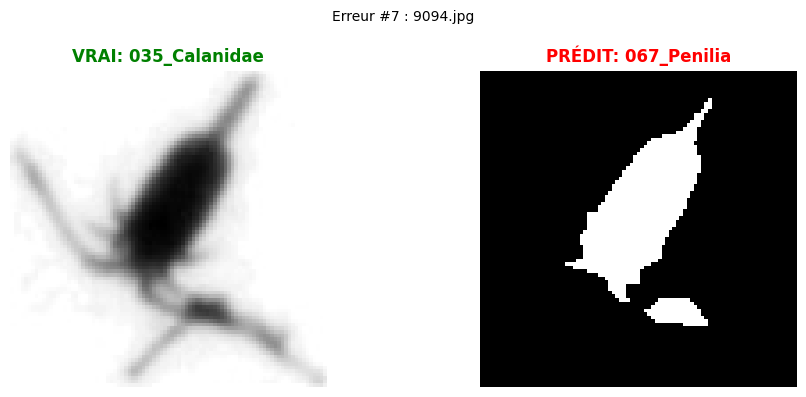

/tmp/ipykernel_1019/575614534.py:71: FutureWarning: Parameter `min_size` is deprecated since version 0.26.0 and will be removed in 2.0.0 (or later). To avoid this warning, please use the parameter `max_size` instead. For more details, see the documentation of `remove_small_objects`. Note that the new threshold removes objects smaller than **or equal to** its value, while the previous parameter only removed smaller ones.
  mask = morphology.remove_small_objects(mask, 50)


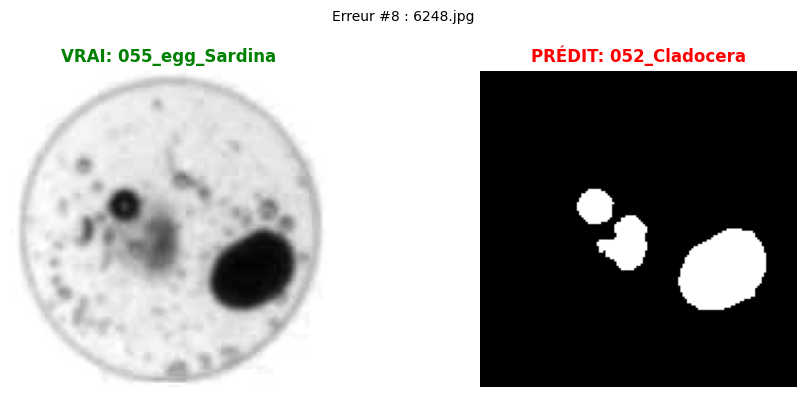

/tmp/ipykernel_1019/575614534.py:71: FutureWarning: Parameter `min_size` is deprecated since version 0.26.0 and will be removed in 2.0.0 (or later). To avoid this warning, please use the parameter `max_size` instead. For more details, see the documentation of `remove_small_objects`. Note that the new threshold removes objects smaller than **or equal to** its value, while the previous parameter only removed smaller ones.
  mask = morphology.remove_small_objects(mask, 50)


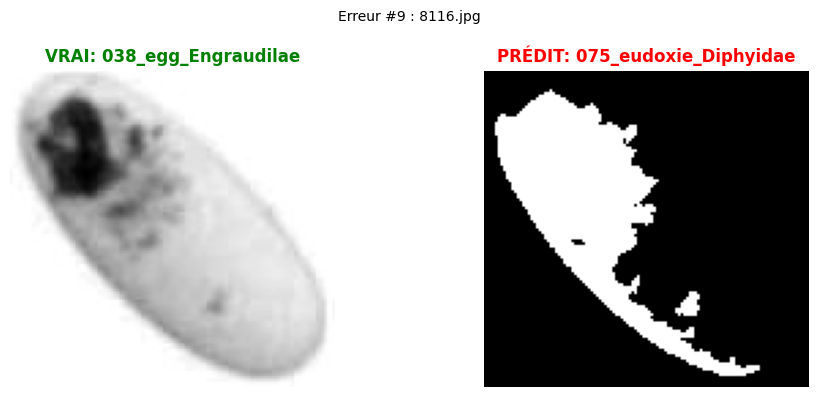

/tmp/ipykernel_1019/575614534.py:71: FutureWarning: Parameter `min_size` is deprecated since version 0.26.0 and will be removed in 2.0.0 (or later). To avoid this warning, please use the parameter `max_size` instead. For more details, see the documentation of `remove_small_objects`. Note that the new threshold removes objects smaller than **or equal to** its value, while the previous parameter only removed smaller ones.
  mask = morphology.remove_small_objects(mask, 50)


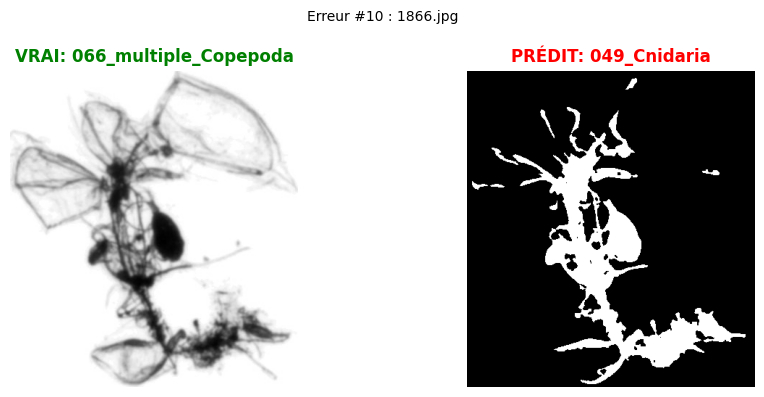

In [18]:
# =============================================================================
# 5. ANALYSE DES ÉCHECS (FAIL CASES) - CORRIGÉ
# =============================================================================
import matplotlib.pyplot as plt

print("\n" + "="*50)
print(" VISUALISATION DES ERREURS (MODEL FAILS)")
print("="*50)

# 1. Sécurisation des formats (Conversion explicite en Numpy Arrays)
y_test_array = np.array(y_test)
y_pred_array = np.array(y_pred)

# Si files_test est une Série Pandas, on prend ses valeurs, sinon on le laisse tel quel
if hasattr(files_test, 'values'):
    files_test_array = files_test.values
else:
    files_test_array = np.array(files_test)

# Vérification de sécurité avant de planter
if len(y_test_array) != len(y_pred_array):
    print(f"ERREUR CRITIQUE DE TAILLE : y_test={len(y_test_array)}, y_pred={len(y_pred_array)}")
    print(">>> RELANCEZ LA CELLULE DE PRÉDICTION (model.predict) <<<")
else:
    # 2. Trouver les indices exacts des erreurs
    # On compare les vecteurs
    error_mask = (y_test_array != y_pred_array)
    error_indices = np.where(error_mask)[0] # Indices numériques (0, 1, 5, ...)

    total_errors = len(error_indices)
    print(f"Nombre total d'erreurs : {total_errors} sur {len(y_test)} images de test.")

    if total_errors > 0:
        # 3. Sélectionner 10 erreurs au hasard
        n_samples = min(10, total_errors)
        random_error_indices = np.random.choice(error_indices, n_samples, replace=False)

        print(f"Affichage de {n_samples} exemples d'erreurs...\n")

        for i, idx in enumerate(random_error_indices):
            # Récupération sécurisée via l'index numpy
            file_path = files_test_array[idx]
            true_label_idx = y_test_array[idx]
            pred_label_idx = y_pred_array[idx]
            
            # Conversion index -> Nom de classe
            true_name = le.inverse_transform([true_label_idx])[0]
            pred_name = le.inverse_transform([pred_label_idx])[0]
            
            # --- RE-SEGMENTATION POUR L'AFFICHAGE ---
            try:
                img = io.imread(file_path)
                
                # Gestion N&B ou Couleur
                if img.ndim == 3: 
                    gray = color.rgb2gray(img)
                else: 
                    gray = img
                    
                # On refait un seuillage simple pour montrer la forme vue par l'ordi
                # (Peut différer légèrement du process complet, mais sert à visualiser)
                val_otsu = filters.threshold_otsu(gray)
                
                # Note: Ajuste cette logique si tes images sont sur fond noir ou blanc
                # Ici on suppose fond blanc (plancton classique) -> objet sombre
                if np.mean(gray) > 0.5: # Fond clair
                    mask = gray < val_otsu
                else: # Fond sombre
                    mask = gray > val_otsu
                
                mask = morphology.remove_small_objects(mask, 50)
                
                # --- AFFICHAGE PLOT ---
                fig, axes = plt.subplots(1, 2, figsize=(10, 4))
                
                # Image Originale
                axes[0].imshow(img, cmap='gray' if img.ndim==2 else None)
                axes[0].set_title(f"VRAI: {true_name}", color='green', fontweight='bold', fontsize=12)
                axes[0].axis('off')
                
                # Masque
                axes[1].imshow(mask, cmap='afmhot') # afmhot permet de bien voir le binaire
                axes[1].set_title(f"PRÉDIT: {pred_name}", color='red', fontweight='bold', fontsize=12)
                axes[1].axis('off')
                
                plt.suptitle(f"Erreur #{i+1} : {os.path.basename(file_path)}", fontsize=10)
                plt.tight_layout()
                plt.show()

            except Exception as e:
                print(f"Impossible d'afficher {file_path}: {e}")
    else:
        print("Incroyable ! 0 erreur. Le modèle est parfait (ou il y a un bug).")


In [ ]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer

# =============================================================================
# 3. PRE-PROCESSING & PCA
# =============================================================================

print(f"Features avant PCA : {X_train.shape[1]}")

# 1. Nettoyage des NaNs (PCA ne supporte pas les valeurs manquantes)
# Si une segmentation a échoué mais pas l'autre, on remplace le vide par la moyenne de la colonne
imputer = SimpleImputer(strategy='mean')
X_train_clean = imputer.fit_transform(X_train)
X_test_clean = imputer.transform(X_test)

# 2. Normalisation (OBLIGATOIRE pour la PCA)
# L'aire (10000px) ne doit pas écraser la circularité (0.5)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_clean)
X_test_scaled = scaler.transform(X_test_clean)

# 3. Application de la PCA
# n_components=0.95 signifie : "Garde-moi 95% de l'information (variance), peu importe le nombre de dimensions"
pca = PCA(n_components=0.95, random_state=42)
X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

print(f"Features après PCA : {X_train_pca.shape[1]} (Compression réussie !)")
print("-" * 30)

# =============================================================================
# 4. ENTRAÎNEMENT XGBOOST (SUR DONNÉES COMPRESSÉES)
# =============================================================================

# Configuration
model = XGBClassifier(
    n_estimators=10,     
    learning_rate=0.05,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    n_jobs=-1,
    random_state=42
    verbose=1
)

print("Lancement de l'entraînement XGBoost sur les composantes PCA...")

# Note: On doit passer X_test_pca dans le eval_set pour qu'il puisse vérifier son score
model.fit(X_train_pca, y_train, 
          eval_set=[(X_test_pca, y_test)], 
          verbose=10)

# =============================================================================
# 5. ÉVALUATION
# =============================================================================

y_pred = model.predict(X_test_pca)

acc = accuracy_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred, average='weighted')

print("-" * 30)
print(f"RÉSULTATS XGBOOST + PCA")
print("-" * 30)
print(f"Accuracy : {acc:.4f}")
print(f"F1-Score : {f1:.4f}")
print("-" * 30)

# Afficher les composantes importantes
# ATTENTION : Avec la PCA, on perd les noms "otsu_area", etc. 
# On a maintenant des "Composantes Principales" (mélange mathématique des features)
importances = model.feature_importances_
indices = np.argsort(importances)[::-1]

print("\nTop 5 Composantes les plus importantes (PC = Principal Component) :")
for i in range(5):
    idx = indices[i]
    # On explique la variance expliquée par cette composante
    explained_var = pca.explained_variance_ratio_[idx]
    print(f"{i+1}. PC_{idx} (Poids: {importances[idx]:.4f}) - Porte {explained_var:.1%} de l'info globale")


Features avant PCA : 27
Features après PCA : 11 (Compression réussie !)
------------------------------
Lancement de l'entraînement XGBoost sur les composantes PCA...
